# GAN lab: from random digits to requested digits

**Completed lab · executed on CUDA with seed 42**

Complete the `TODO` functions, run the checks, and investigate how adversarial training behaves. The architectures, data handling, and plotting are supplied. Prerequisites: PyTorch modules, autograd, binary cross-entropy, and the GAN lectures.

By the end you should be able to implement alternating updates, explain gradient flow, compare a controlled intervention, and condition generation on digit identity.

| Part | Work | Suggested active time |
|---|---|---|
| A | Complete and check the training steps | 40 min |
| B | Train a vanilla GAN and inspect samples | 25 min |
| C | Change only the discriminator learning rate | 35 min |
| D | Complete conditional inputs and inspect control/diversity | 50 min |
| E | Interpret and submit results | 30 min |

Training time depends on hardware. Short runs are not guaranteed to produce recognizable digits. No pretrained weights or measured results are bundled.

Execution note: the two-batch smoke run passed first. The saved outputs below are full runs: 60,000 MNIST training images, 10 epochs per experiment, batch size 128, no pretrained weights. All four implementation exercises and the written responses are completed.


## Setup: Kaggle or local Jupyter

- **Kaggle:** upload this notebook, enable a GPU accelerator, and enable internet for the initial MNIST download. For offline use, attach original MNIST IDX files (plain or gzip); CSV-only datasets are not supported.
- **Local:** open with a Python 3 Jupyter kernel containing `torch`, `torchvision`, and `matplotlib`. CPU works, but convolutional training can be slow. If needed, run the optional installation cell and restart the kernel.
- Output goes to `/kaggle/working/gan_lab_student` on Kaggle or `./gan_lab_student` locally (the solution uses its own folder). Repeating a run name overwrites that run's artifacts.
- First complete the TODOs and run with `SMOKE_TEST=True`. Then set it to `False` and rerun from the configuration cell. Smoke mode uses two batches and one epoch; it checks execution, not learning.
- Offline locally, put original IDX files under `DATA_DIR/MNIST/raw` or set `OFFLINE_MNIST_DIR` to their parent directory. Both training and test image/label files are recommended for torchvision compatibility.

Reference lectures: `module1/lectures/gans/gan_basics.md`, `dcgan-lecture-notes.md`, and `conditional_gan.md`. Paths describe the repository; this notebook is otherwise self-contained.


In [5]:
# Optional: uncomment only if dependencies are missing.
# %pip install torch torchvision matplotlib


In [6]:
from pathlib import Path
import gzip
import shutil
import json
import time
import random
import os
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
import matplotlib.pyplot as plt

SEED = 42
LATENT_DIM, NUM_CLASSES, IMG_SIZE = 100, 10, 32
IMG_DIM = 28 * 28
BATCH_SIZE = 128
LR = 2e-4
BASELINE_EPOCHS = 10
CONDITIONAL_EPOCHS = 10
SMOKE_TEST = False
# Optional smaller training subset for limited hardware; use the same value for all runs.
TRAIN_LIMIT = None
OFFLINE_MNIST_DIR = None  # Example: Path('/path/to/mnist-files')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
WORK_DIR = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
# Reuse repository MNIST data when running from the notebook directory.
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / 'generative_ai_shared').is_dir()), WORK_DIR)
DATA_DIR = REPO_ROOT / 'data'
OUTPUT_DIR = WORK_DIR / 'gan_lab_student'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_all(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Avoid CPU thread oversubscription on local machines.
if DEVICE.type == 'cpu':
    torch.set_num_threads(min(4, os.cpu_count() or 1))

seed_all(SEED)
print('Device:', DEVICE, '| Smoke mode:', SMOKE_TEST)
print('Outputs:', OUTPUT_DIR.resolve())


Device: cuda | Smoke mode: False
Outputs: /home/jiwak/GenAi_Notes/Gen_AI_Lab/generative_ai_shared/module1/labs/gans/gan_lab_student


## A. Alternating adversarial updates

Both discriminators in this lab return **logits**, with no final sigmoid. Use `BCEWithLogitsLoss` directly. This is equivalent in objective to the sigmoid + `BCELoss` formulation in the vanilla reference, with a numerically stable implementation.

For discriminator logits $s_r$ on real images and $s_f$ on generated images:

$$L_D=\operatorname{BCELogits}(s_r,1)+\operatorname{BCELogits}(s_f,0).$$

For the generator, recompute generated images and minimize:

$$L_G=\operatorname{BCELogits}(D(G(z)),1).$$

**TODO A1:** implement `discriminator_step`. Clear gradients, generate and detach fakes, compute both losses, backpropagate, and step only `opt_d`.

**TODO A2:** implement the marked generator block. Do not detach its fake images. The supplied wrapper freezes D's parameters and BatchNorm statistics while retaining autograd through D. Evaluation mode does not disable gradients.

`labels=None` means unconditional generation. Otherwise pass the class labels to both networks; these digit IDs are inputs, not BCE targets.


In [7]:
class VanillaGenerator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, img_dim=IMG_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, img_dim),
            nn.Tanh()          # output range [-1, 1]
        )

    def forward(self, z):
        return self.net(z)


# ----------------------------
# Discriminator: image -> real/fake logit
# ----------------------------
class VanillaDiscriminator(nn.Module):
    def __init__(self, img_dim=IMG_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(img_dim, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
        )

    def forward(self, x):
        return self.net(x)


In [8]:
criterion = nn.BCEWithLogitsLoss()

def generate(g, z, labels=None):
    return g(z) if labels is None else g(z, labels)

def discriminate(d, images, labels=None):
    return d(images) if labels is None else d(images, labels)

def discriminator_step(g, d, opt_g, opt_d, real, labels=None):
    g.train()
    d.train()
    opt_g.zero_grad(set_to_none=True)
    opt_d.zero_grad(set_to_none=True)
    z = torch.randn(real.size(0), LATENT_DIM, device=real.device)
    fake = generate(g, z, labels).detach()
    real_logits = discriminate(d, real, labels)
    fake_logits = discriminate(d, fake, labels)
    loss = (criterion(real_logits, torch.ones_like(real_logits))
            + criterion(fake_logits, torch.zeros_like(fake_logits)))
    loss.backward()
    opt_d.step()
    return loss.item()

def generator_step(g, d, opt_g, opt_d, batch_size, labels=None):
    g.train()
    opt_g.zero_grad(set_to_none=True)
    opt_d.zero_grad(set_to_none=True)
    previous_mode = d.training
    d.requires_grad_(False)
    d.eval()
    try:
        device = next(g.parameters()).device
        z = torch.randn(batch_size, LATENT_DIM, device=device)
        fake = generate(g, z, labels)
        logits = discriminate(d, fake, labels)
        loss = criterion(logits, torch.ones_like(logits))
        loss.backward()
        opt_g.step()
        return loss.item()
    finally:
        d.requires_grad_(True)
        d.train(previous_mode)


### Check gradient flow before downloading data

These checks use temporary networks and synthetic images. They verify that D's step leaves G's parameters and gradients alone, while G's step changes G without changing D's parameters or BatchNorm buffers. Passing does not establish generation quality.


In [9]:
def snapshot(module):
    return {k: v.detach().clone() for k, v in module.state_dict().items()}

def check_updates(g, d, real, labels=None):
    opt_g = torch.optim.Adam(g.parameters(), lr=LR, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(d.parameters(), lr=LR, betas=(0.5, 0.999))
    before_g = {k: p.detach().clone() for k, p in g.named_parameters()}
    before_d = {k: p.detach().clone() for k, p in d.named_parameters()}
    dl = discriminator_step(g, d, opt_g, opt_d, real, labels)
    assert all(torch.equal(before_g[k], p) for k, p in g.named_parameters()), 'G updated in D step'
    assert all(p.grad is None for p in g.parameters()), 'Detach fakes in D step'
    assert any(not torch.equal(before_d[k], p) for k, p in d.named_parameters()), 'D did not update'
    d_state = snapshot(d)
    gl = generator_step(g, d, opt_g, opt_d, real.size(0), labels)
    assert any(not torch.equal(before_g[k], p) for k, p in g.named_parameters()), 'G did not update'
    assert all(torch.equal(d_state[k], v) for k, v in d.state_dict().items()), 'D changed in G step'
    assert all(p.grad is None for p in d.parameters()), 'D gradients should remain disabled'
    assert torch.isfinite(torch.tensor([dl, gl])).all()
    print('Update checks passed:', {'D': dl, 'G': gl})

seed_all(SEED)
check_updates(VanillaGenerator().to(DEVICE), VanillaDiscriminator().to(DEVICE),
              torch.rand(4, IMG_DIM, device=DEVICE) * 2 - 1)


Update checks passed: {'D': 1.3750903606414795, 'G': 0.682660698890686}


**Answer A:** The generator targets 1 because it should make D classify its outputs as real; this is the non-saturating generator objective. Detaching fakes in D's step blocks gradients into G while D learns. In G's step, the computation through D must remain differentiable so its input gradients reach G. Freezing D's parameters prevents their update but preserves this path. Wrapping D's forward pass in `torch.no_grad()` would sever the path and make the generator loss unable to backpropagate.


## B. Load MNIST and train the baseline

Use 28 × 28 images for the supplied MLP and 32 × 32 for the conditional convolutional model. Normalize real pixels to [-1, 1] to match `Tanh`. The architectures differ in both resolution and capacity; do not interpret their comparison as an isolated test of conditioning.

Data order uses a separate seeded generator, so baseline and intervention see matching batches. A fixed random subset is used if `TRAIN_LIMIT` is set. Seeds improve repeatability but do not promise identical results across devices.


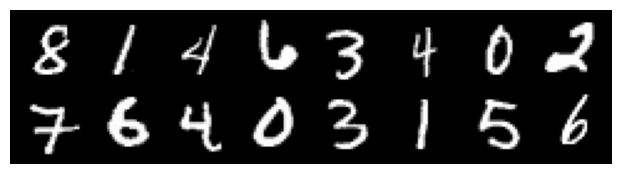

Training examples: 60000


In [10]:
raw_dir = DATA_DIR / "MNIST" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)
input_dir = Path(OFFLINE_MNIST_DIR) if OFFLINE_MNIST_DIR is not None else Path("/kaggle/input")
raw_names = [
    "train-images-idx3-ubyte", "train-labels-idx1-ubyte",
    "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte",
]
for name in raw_names:
    destination = raw_dir / name
    if destination.exists() or not input_dir.exists():
        continue
    aliases = [name, name.replace("-idx", ".idx")]
    candidates = sorted({path for alias in aliases
                         for pattern in (alias, alias + ".gz")
                         for path in input_dir.rglob(pattern) if path.is_file()})
    if candidates:
        source = candidates[0]
        opener = gzip.open if source.suffix == ".gz" else open
        with opener(source, "rb") as src, destination.open("wb") as dst:
            shutil.copyfileobj(src, dst)
        print("Loaded attached file:", source)

def load_mnist(size):
    transform = transforms.Compose([
        transforms.Resize(size), transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,)),
    ])
    try:
        return datasets.MNIST(str(DATA_DIR), train=True, download=False, transform=transform)
    except RuntimeError:
        try:
            return datasets.MNIST(str(DATA_DIR), train=True, download=True, transform=transform)
        except Exception as exc:
            raise RuntimeError('MNIST unavailable. Enable internet or supply original IDX files '
                               'using OFFLINE_MNIST_DIR (Kaggle: attach under /kaggle/input).') from exc

def make_loader(size):
    dataset = load_mnist(size)
    limit = 2 * BATCH_SIZE if SMOKE_TEST else TRAIN_LIMIT
    if limit is not None:
        assert isinstance(limit, int) and limit >= 2, 'Use at least two examples'
        indices = torch.randperm(len(dataset), generator=torch.Generator().manual_seed(SEED))
        dataset = Subset(dataset, indices[:min(limit, len(dataset))].tolist())
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                      generator=torch.Generator().manual_seed(SEED),
                      pin_memory=(DEVICE.type == 'cuda'))

preview_loader = make_loader(28)
real_images, real_labels = next(iter(preview_loader))
assert real_images.shape[1:] == (1, 28, 28)
assert -1 <= real_images.min() and real_images.max() <= 1
plt.figure(figsize=(8, 2))
plt.imshow(make_grid((real_images[:16] + 1) / 2, nrow=8).permute(1, 2, 0))
plt.axis('off')
plt.show()
print('Training examples:', len(preview_loader.dataset))


### Supplied experiment runner

Each call resets the seed and creates fresh models, optimizers, and data order. It saves fixed-noise sample grids (including epoch zero), sample-weighted epoch losses, configuration, elapsed training time, and a checkpoint. Fixed noise is identical between the two vanilla runs. D loss is the **sum** of real and fake BCE terms; G loss has one term, so their numerical values are not directly comparable.

Start with the smoke run, then run a meaningful training budget. Use sample realism and variety alongside losses. A checkpoint from smoke mode remains essentially untrained.


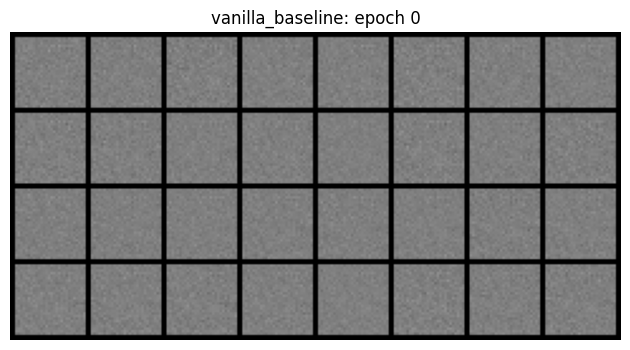

vanilla_baseline 1/10 | D=1.1814 G=0.9549


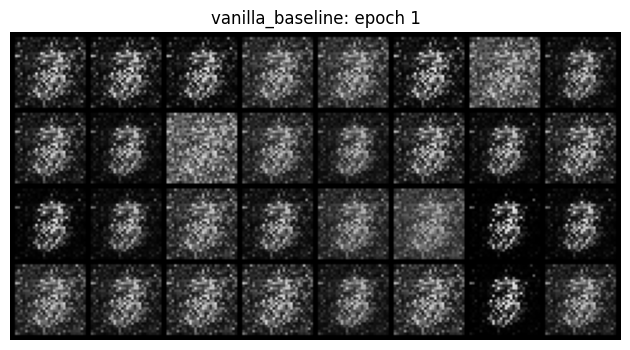

vanilla_baseline 2/10 | D=0.9088 G=1.7695
vanilla_baseline 3/10 | D=0.8623 G=2.0127
vanilla_baseline 4/10 | D=0.8496 G=1.9803
vanilla_baseline 5/10 | D=0.8240 G=2.0909


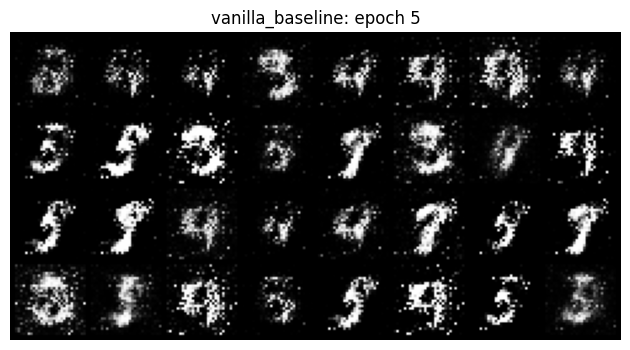

vanilla_baseline 6/10 | D=0.8769 G=1.8951
vanilla_baseline 7/10 | D=0.8905 G=1.8758
vanilla_baseline 8/10 | D=0.8340 G=1.7998
vanilla_baseline 9/10 | D=0.8383 G=1.9753
vanilla_baseline 10/10 | D=0.8376 G=1.9063


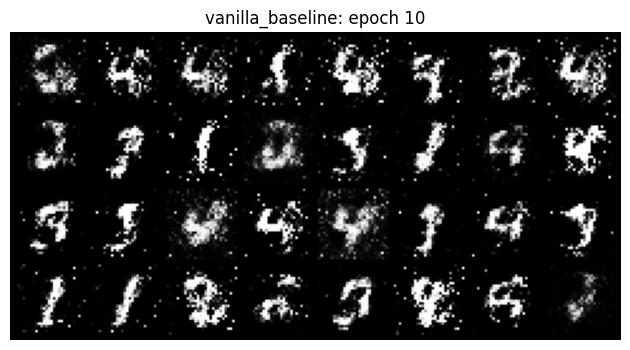

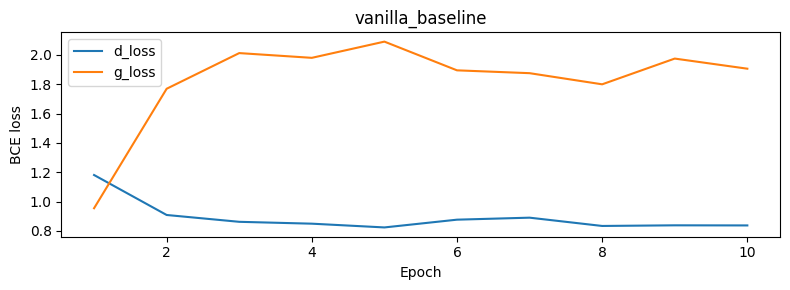

In [11]:
@torch.no_grad()
def sample(g, noise, labels=None):
    previous_mode = g.training
    g.eval()
    try:
        images = generate(g, noise, labels)
        if images.ndim == 2:
            images = images.reshape(-1, 1, 28, 28)
        return ((images.cpu() + 1) / 2).clamp(0, 1)
    finally:
        g.train(previous_mode)

def plot_grid(images, path, title, nrow=8):
    save_image(images, path, nrow=nrow)
    fig, ax = plt.subplots(figsize=(8, 8 if len(images) == 80 else 4))
    ax.imshow(make_grid(images, nrow=nrow).permute(1, 2, 0), vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')
    plt.show()
    plt.close(fig)

def run_experiment(name, conditional=False, d_lr_multiplier=1.0):
    seed_all(SEED)
    folder = OUTPUT_DIR / name
    folder.mkdir(parents=True, exist_ok=True)
    if conditional:
        g = ConditionalGenerator().to(DEVICE).apply(weights_init)
        d = ConditionalDiscriminator().to(DEVICE).apply(weights_init)
    else:
        g, d = VanillaGenerator().to(DEVICE), VanillaDiscriminator().to(DEVICE)
    opt_g = torch.optim.Adam(g.parameters(), lr=LR, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(d.parameters(), lr=LR * d_lr_multiplier, betas=(0.5, 0.999))
    loader = make_loader(32 if conditional else 28)
    epochs = 1 if SMOKE_TEST else (CONDITIONAL_EPOCHS if conditional else BASELINE_EPOCHS)
    sample_rng = torch.Generator().manual_seed(SEED + 1)
    if conditional:
        fixed_z = torch.randn(8, LATENT_DIM, generator=sample_rng).repeat(10, 1).to(DEVICE)
        fixed_y = torch.arange(10, device=DEVICE).repeat_interleave(8)
    else:
        fixed_z = torch.randn(32, LATENT_DIM, generator=sample_rng).to(DEVICE)
        fixed_y = None
    def record(epoch):
        title = f'{name}: epoch {epoch}'
        if conditional:
            title += ' | requested digits 0–9 from top to bottom'
        plot_grid(sample(g, fixed_z, fixed_y), folder / f'epoch_{epoch:03d}.png', title)
    record(0)
    history = {'d_loss': [], 'g_loss': []}
    started = time.perf_counter()
    for epoch in range(1, epochs + 1):
        d_total = g_total = seen = 0
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE) if conditional else None
            if not conditional:
                images = images.flatten(1)
            dl = discriminator_step(g, d, opt_g, opt_d, images, labels)
            gl = generator_step(g, d, opt_g, opt_d, len(images), labels)
            assert torch.isfinite(torch.tensor([dl, gl])).all(), 'Non-finite loss'
            d_total += dl * len(images)
            g_total += gl * len(images)
            seen += len(images)
        history['d_loss'].append(d_total / seen)
        history['g_loss'].append(g_total / seen)
        print(f"{name} {epoch}/{epochs} | D={d_total/seen:.4f} G={g_total/seen:.4f}")
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            record(epoch)
    elapsed = time.perf_counter() - started
    config = dict(name=name, conditional=conditional, seed=SEED, latent_dim=LATENT_DIM,
                  num_classes=NUM_CLASSES, image_size=32 if conditional else 28,
                  batch_size=BATCH_SIZE, g_lr=LR, d_lr=LR*d_lr_multiplier,
                  epochs=epochs, training_examples=len(loader.dataset), smoke_test=SMOKE_TEST,
                  train_limit=TRAIN_LIMIT, device=str(DEVICE))
    torch.save(dict(generator=g.state_dict(), discriminator=d.state_dict(),
                    optimizer_g=opt_g.state_dict(), optimizer_d=opt_d.state_dict(),
                    config=config, history=history), folder / 'checkpoint.pt')
    (folder / 'results.json').write_text(json.dumps(
        dict(config=config, history=history, elapsed_seconds=elapsed), indent=2))
    fig, ax = plt.subplots(figsize=(8, 3))
    for key, values in history.items():
        ax.plot(range(1, epochs + 1), values, label=key)
    ax.set(xlabel='Epoch', ylabel='BCE loss', title=name)
    ax.legend()
    fig.tight_layout()
    fig.savefig(folder / 'losses.png')
    plt.show()
    plt.close(fig)
    return dict(generator=g, discriminator=d, history=history, folder=folder,
                config=config, elapsed_seconds=elapsed, fixed_z=fixed_z, fixed_y=fixed_y)

baseline = run_experiment('vanilla_baseline')


**Observation B:** `vanilla_baseline/epoch_000.png` contains unstructured noise. At epoch one (`epoch_001.png`), coarse bright blobs and occasional loops appear, but most samples are not readable digits. At epoch ten (`epoch_010.png`), several samples resemble 1, 2, 4, 7, or 9, with varied shapes, though many are speckled, broken, or ambiguous. This is partial learning rather than consistently realistic handwriting.

D loss changes from 1.1814 to 0.8376; G loss changes from 0.9549 to 1.9063. G loss rises even while the images become more digit-like. Adversarial losses depend on the changing opponent and cannot certify realism or class coverage. These are full training outputs, not smoke outputs.


## C. Controlled intervention: a faster discriminator

Keep G's learning rate at 0.0002 and increase only D's learning rate by a factor of five. Use the same initialization, batch order, dataset, and number of updates as the baseline. Do not continue training the baseline model.

**Before running:** predict how D/G losses and samples might change, and explain your reasoning. Then run the comparison. A stronger discriminator or mode collapse is not guaranteed; report what happened.

*Prediction (before execution):* Increasing only D's learning rate may let it distinguish real and fake images sooner, lowering D loss and increasing G loss early on. G may receive a more difficult or less stable learning signal. Sample quality could improve or deteriorate; collapse is a possibility, not a necessary outcome. The same seed, subset, batch order, and update count isolate the learning-rate intervention within these runs.


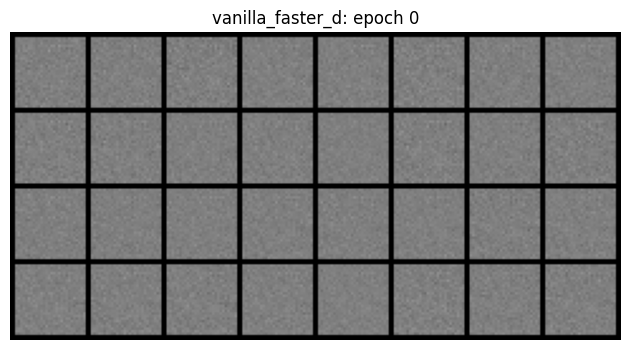

vanilla_faster_d 1/10 | D=0.8633 G=1.5837


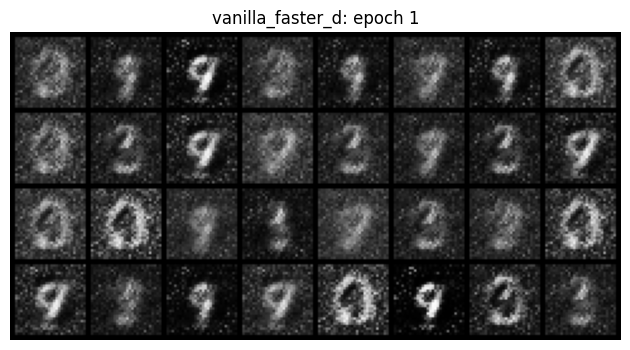

vanilla_faster_d 2/10 | D=0.8430 G=2.0206
vanilla_faster_d 3/10 | D=0.8269 G=2.0580
vanilla_faster_d 4/10 | D=0.7534 G=2.2368
vanilla_faster_d 5/10 | D=0.7054 G=2.2910


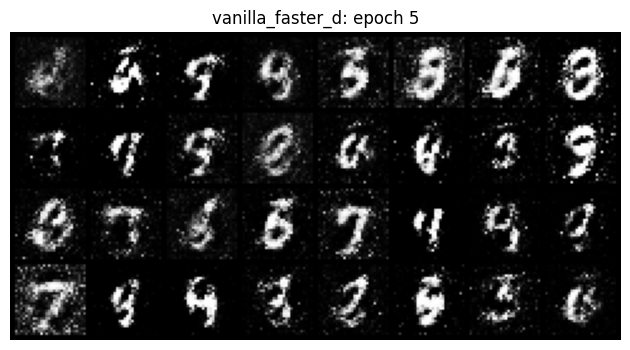

vanilla_faster_d 6/10 | D=0.6548 G=2.3967
vanilla_faster_d 7/10 | D=0.7190 G=2.2068
vanilla_faster_d 8/10 | D=0.7889 G=1.9436
vanilla_faster_d 9/10 | D=0.8295 G=1.8083
vanilla_faster_d 10/10 | D=0.8463 G=1.7850


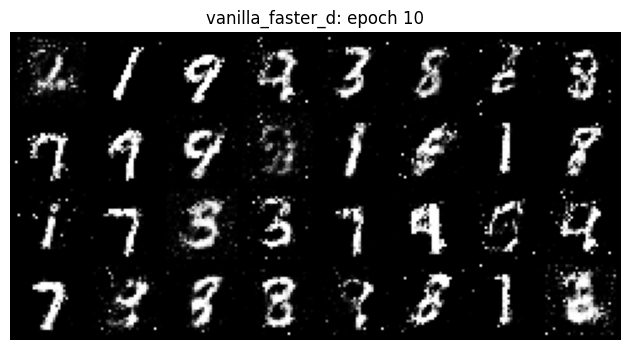

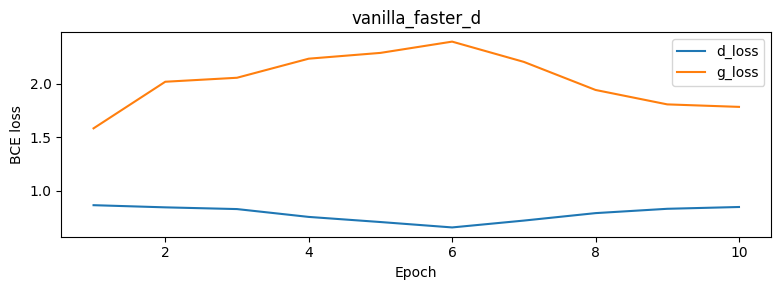

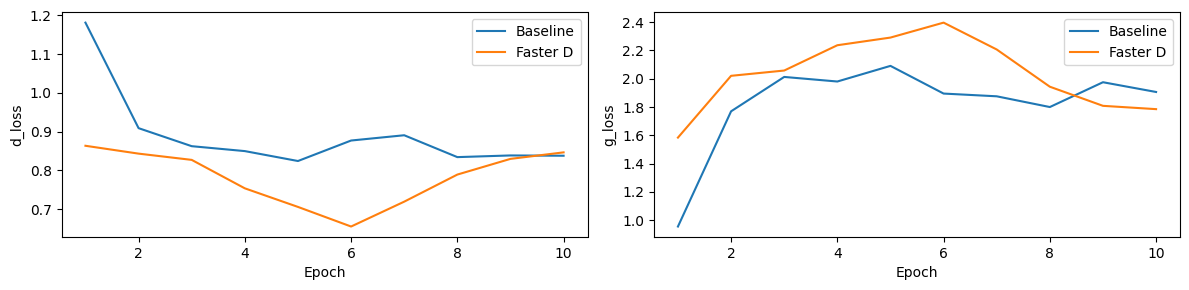

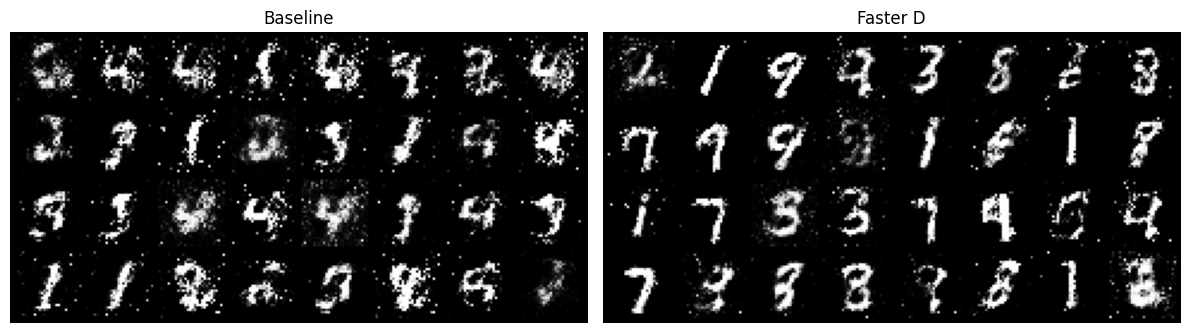

In [12]:
intervention = run_experiment('vanilla_faster_d', d_lr_multiplier=5.0)

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, key in zip(axes, ['d_loss', 'g_loss']):
    for label, result in [('Baseline', baseline), ('Faster D', intervention)]:
        values = result['history'][key]
        ax.plot(range(1, len(values) + 1), values, label=label)
    ax.set(xlabel='Epoch', ylabel=key)
    ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'intervention_losses.png')
plt.show()
plt.close(fig)

# Identical noise and layout for final sample comparison.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, label, result in zip(axes, ['Baseline', 'Faster D'], [baseline, intervention]):
    images = sample(result['generator'], baseline['fixed_z'])
    ax.imshow(make_grid(images, nrow=8).permute(1, 2, 0))
    ax.set_title(label)
    ax.axis('off')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'intervention_samples.png')
plt.show()
plt.close(fig)


**Observation C:**

| Run | Realism | Variety / possible repeated modes | Loss behavior |
|---|---|---|---|
| Baseline | Some recognizable digits, but substantial speckle and malformed strokes | Several apparent digit shapes; repeated narrow strokes and 4-like shapes; coverage uncertain | Final D=0.8376, G=1.9063; losses fluctuate |
| Faster D | Cleaner strokes and more legible digits in the matched final grid; some ambiguous outputs remain | Visibly different shapes including 1-, 3-, 7-, 8-, and 9-like samples; repetitions do not establish collapse | Final D=0.8463, G=1.7850; D falls and G rises in the middle epochs, then the trend reverses |

The early direction supports the prediction: faster D has lower first-epoch D loss (0.8633 versus 1.1814) and higher G loss (1.5837 versus 0.9549). However, its final samples look better, so this run does not support the claim that a faster discriminator necessarily damages generation. See `intervention_losses.png` and `intervention_samples.png` for matching evidence.

Limitation: one seed and 32 fixed-noise samples provide weak evidence about overall realism and mode coverage. A useful follow-up is to repeat both settings over multiple seeds, inspect larger matched grids, and measure class frequencies with an independent MNIST classifier while also assessing image quality.


## D. Conditional DCGAN: request a digit

Complete the two conditioning helpers. The supplied convolutional architectures call them.

- **TODO D1:** one-hot encode labels, match noise dtype, and concatenate with noise. Return `(B, 110, 1, 1)` for the default latent dimension.
- **TODO D2:** one-hot encode labels, expand to constant spatial maps, and concatenate with images. Return `(B, 11, 32, 32)`.

Use `F.one_hot(..., num_classes=NUM_CLASSES)`, `torch.cat`, and broadcasting/`expand`. Both networks receive the same class condition. D returns one real/fake logit per pair, not ten class logits.


In [13]:
def condition_noise(noise, labels):
    one_hot = F.one_hot(labels, num_classes=NUM_CLASSES).to(noise)
    return torch.cat((noise, one_hot), dim=1)[:, :, None, None]

def condition_images(images, labels):
    one_hot = F.one_hot(labels, num_classes=NUM_CLASSES).to(images)
    maps = one_hot[:, :, None, None].expand(-1, -1, images.size(2), images.size(3))
    return torch.cat((images, maps), dim=1)


In [14]:
class ConditionalGenerator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, num_classes=NUM_CLASSES):
        super().__init__()
        self.num_classes = num_classes
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim + num_classes, 256, 4, 1, 0, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False),
            nn.Tanh(),  # Match normalized real pixels in [-1, 1].
        )

    def forward(self, noise, class_labels):
        return self.net(condition_noise(noise, class_labels))


class ConditionalDiscriminator(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.num_classes = num_classes
        self.net = nn.Sequential(
            # input dimension (1 + num_classes) x 32 x 32 -> output dimension 64 x 16 x 16
            nn.Conv2d(in_channels=1 + num_classes, out_channels=64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # input dimension 64 x 16 x 16 -> output dimension 128 x 8 x 8
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            # input dimension 128 x 8 x 8 -> output dimension 256 x 4 x 4
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256), nn.LeakyReLU(0.2, inplace=True),
            # input dimension 256 x 4 x 4 -> output dimension 1 x 1 x 1
            # A single scalar output (logit) for each image in the batch, indicating real/fake.
            nn.Conv2d(in_channels=256, out_channels=1, kernel_size=4, stride=1, padding=0, bias=False),
        )

    def forward(self, images, class_labels):
        return self.net(condition_images(images, class_labels)).flatten(1)


def weights_init(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)


Update checks passed: {'D': 1.273191213607788, 'G': 0.6661598682403564}


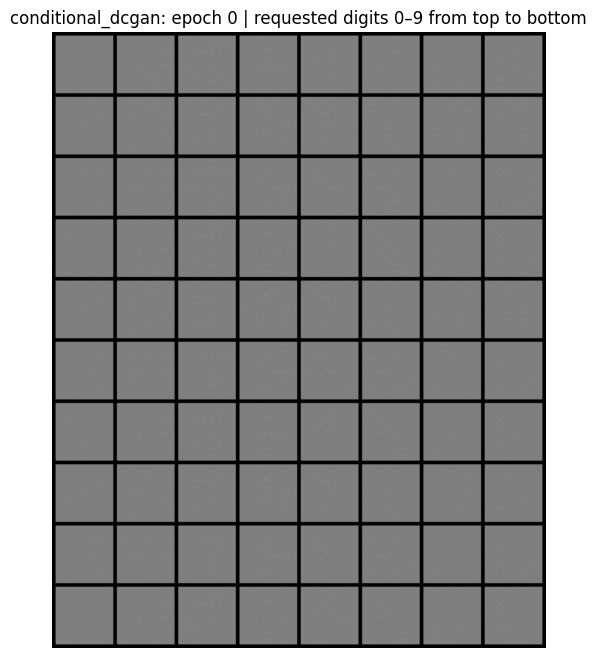

conditional_dcgan 1/10 | D=0.2505 G=1.2863


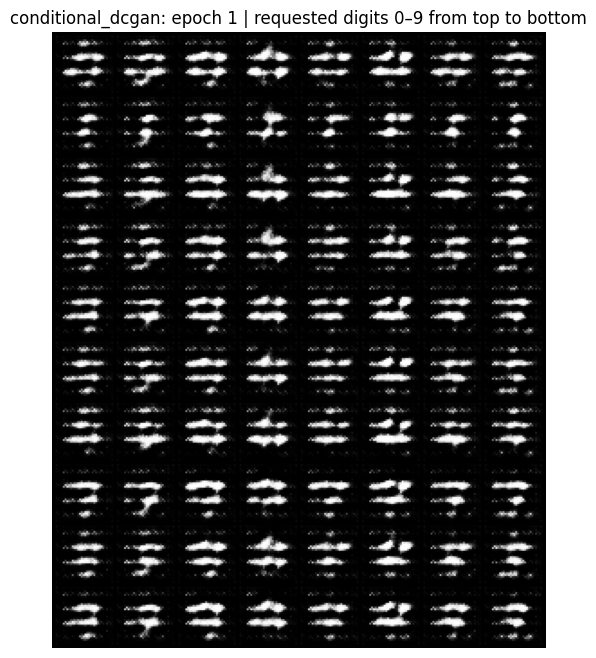

conditional_dcgan 2/10 | D=0.0290 G=0.4419
conditional_dcgan 3/10 | D=0.0425 G=0.1216
conditional_dcgan 4/10 | D=0.0005 G=0.0138
conditional_dcgan 5/10 | D=0.0178 G=0.0624


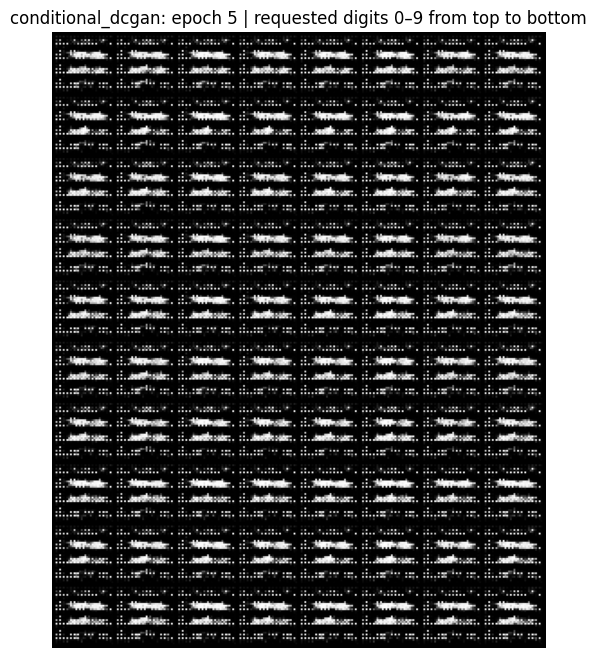

conditional_dcgan 6/10 | D=0.0002 G=0.0050
conditional_dcgan 7/10 | D=0.0001 G=0.0064
conditional_dcgan 8/10 | D=0.0001 G=0.0038
conditional_dcgan 9/10 | D=0.0002 G=0.0024
conditional_dcgan 10/10 | D=0.0368 G=0.0661


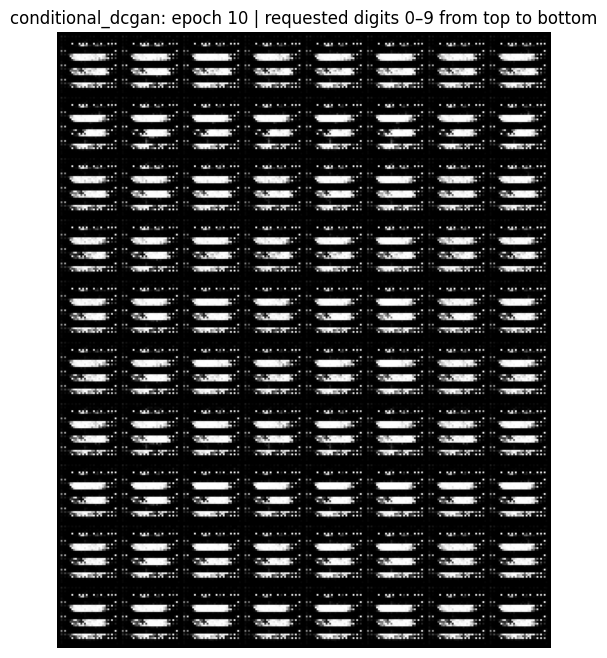

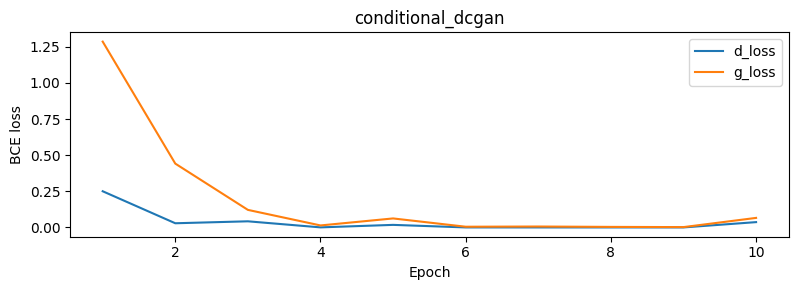

In [15]:
seed_all(SEED)
labels = torch.tensor([0, 3, 7, 9], device=DEVICE)
noise = torch.randn(4, LATENT_DIM, device=DEVICE)
images = torch.rand(4, 1, IMG_SIZE, IMG_SIZE, device=DEVICE) * 2 - 1
conditioned_z = condition_noise(noise, labels)
conditioned_x = condition_images(images, labels)
expected = F.one_hot(labels, NUM_CLASSES).float()
assert conditioned_z.shape == (4, LATENT_DIM + NUM_CLASSES, 1, 1)
assert torch.equal(conditioned_z[:, :LATENT_DIM, 0, 0], noise)
assert torch.equal(conditioned_z[:, LATENT_DIM:, 0, 0], expected)
assert conditioned_x.shape == (4, 11, IMG_SIZE, IMG_SIZE)
assert torch.equal(conditioned_x[:, :1], images)
assert torch.equal(conditioned_x[:, 1:], expected[:, :, None, None].expand(-1, -1, IMG_SIZE, IMG_SIZE))
test_g = ConditionalGenerator().to(DEVICE).apply(weights_init)
test_d = ConditionalDiscriminator().to(DEVICE).apply(weights_init)
with torch.no_grad():
    generated = test_g(noise, labels)
    assert generated.shape == images.shape
    assert generated.min() >= -1 and generated.max() <= 1
    assert test_d(generated, labels).shape == (4, 1)
check_updates(test_g, test_d, images, labels)
del test_g, test_d

conditional = run_experiment('conditional_dcgan', conditional=True)


### Separate control from diversity

Each training grid has ten rows requesting digits 0–9. Columns reuse the same noise across classes; this does not guarantee a shared handwriting style.

Now make two explicit probes: (1) fix the label and vary noise; (2) fix one noise vector and vary the label. Change `REQUESTED_DIGIT` and repeat. Judge realism, class agreement, and within-class diversity separately.


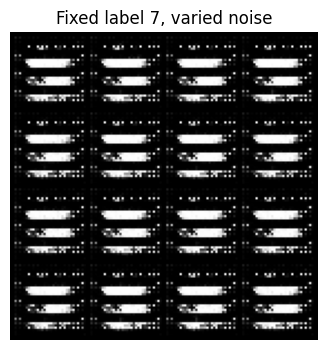

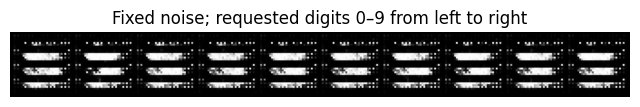

In [16]:
REQUESTED_DIGIT = 7
assert isinstance(REQUESTED_DIGIT, int) and 0 <= REQUESTED_DIGIT < NUM_CLASSES
probe_rng = torch.Generator().manual_seed(SEED + 2)
varying_z = torch.randn(16, LATENT_DIM, generator=probe_rng).to(DEVICE)
fixed_label = torch.full((16,), REQUESTED_DIGIT, dtype=torch.long, device=DEVICE)
plot_grid(sample(conditional['generator'], varying_z, fixed_label),
          conditional['folder'] / f'fixed_label_{REQUESTED_DIGIT}.png',
          f'Fixed label {REQUESTED_DIGIT}, varied noise', nrow=4)
fixed_z = torch.randn(1, LATENT_DIM, generator=probe_rng).repeat(10, 1).to(DEVICE)
varying_labels = torch.arange(NUM_CLASSES, device=DEVICE)
plot_grid(sample(conditional['generator'], fixed_z, varying_labels),
          conditional['folder'] / 'fixed_noise.png',
          'Fixed noise; requested digits 0–9 from left to right', nrow=10)


**Answer D:**

1. A model ignoring labels would produce the same apparent digit or distribution as the requested class changes at fixed noise. A model ignoring noise would produce nearly identical outputs for many noise vectors at a fixed label. Both must be assessed across multiple probes; class-dependent texture changes alone do not show correct digit control.
2. D must see the condition to judge whether an image is plausible for the requested class. An unconditional discriminator can reward realistic digits even when they disagree with the label.
3. D solves binary real/fake discrimination for an image-label pair, so it returns one logit. Ten outputs would instead describe a different objective such as digit classification.
4. This run failed to produce realistic, correctly conditioned digits. `conditional_dcgan/epoch_010.png` shows repetitive horizontal textures across the requested classes. `fixed_label_7.png` contains almost identical textured shapes across 16 noise vectors, providing evidence of severe loss of within-class diversity. `fixed_noise.png` shows small texture changes as labels vary, but no recognizable sequence of digits 0–9. Thus neither semantic class control nor useful diversity is established.

Low conditional losses are misleading here: D is trained in train mode, while G receives gradients through D in eval mode. D's BatchNorm therefore uses batch statistics in one step and running statistics in the other. This is a plausible contributor to the inconsistent loss signals, not a diagnosed cause. A controlled follow-up could use a discriminator without BatchNorm (for example, replace it with GroupNorm), retain the original run as a reference, and repeat the checks and probes. The supplied architecture and training-mode policy were preserved for this lab.


## E. Submission and optional extensions

Submit this completed notebook with outputs and a short conclusion (about 200–300 words). Include baseline/intervention loss plots, matching sample grids, both conditional probes, and the configuration/seed. Clearly identify smoke runs and any externally supplied checkpoints or results. Do not claim learned image quality from smoke runs.

| Assessment | Weight |
|---|---:|
| Correct implementation and gradient-flow explanations | 40% |
| Controlled experiment and visual evidence | 35% |
| Interpretation, conditioning analysis, and limitations | 25% |

**Optional:** compare against the existing unconditional DCGAN notebook; remove generator BatchNorm in a controlled experiment; try CIFAR-10; or measure class agreement using an independent classifier (which is not a complete measure of realism/diversity). These are not required for the core lab.

Artifacts are in `OUTPUT_DIR`. Checkpoints include model and optimizer states, but not full RNG/data-loader state for exact replay. The cell below illustrates loading your own checkpoint for inference after defining the architectures.


In [17]:
# Optional reload of the conditional model trained above.
checkpoint_path = conditional['folder'] / 'checkpoint.pt'
checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
restored_g = ConditionalGenerator(
    latent_dim=checkpoint['config']['latent_dim'],
    num_classes=checkpoint['config']['num_classes'],
).to(DEVICE)
restored_g.load_state_dict(checkpoint['generator'])
restored_g.eval()
# State must match exactly; GPU inference can differ slightly with memory layout.
assert all(torch.equal(value, conditional['generator'].state_dict()[key])
           for key, value in restored_g.state_dict().items())
restored_samples = sample(restored_g, fixed_z, varying_labels)
original_samples = sample(conditional['generator'], fixed_z, varying_labels)
max_difference = (restored_samples - original_samples).abs().max().item()
print('Maximum reload sample difference:', max_difference)
torch.testing.assert_close(restored_samples, original_samples, atol=1e-5, rtol=1e-4)
print('Checkpoint reload verified. Artifacts:', OUTPUT_DIR.resolve())


Maximum reload sample difference: 5.960464477539063e-08
Checkpoint reload verified. Artifacts: /home/jiwak/GenAi_Notes/Gen_AI_Lab/generative_ai_shared/module1/labs/gans/gan_lab_student


### Conclusion

I implemented alternating discriminator and generator updates using binary cross-entropy on logits, together with one-hot conditioning for noise and image channels. The synthetic checks confirmed that the discriminator update leaves generator parameters and gradients untouched, and the generator update changes the generator without changing discriminator parameters or BatchNorm buffers. A two-batch smoke run passed before full training.

The reported experiments use all 60,000 MNIST training examples, seed 42, batch size 128, and ten epochs per model. Adam uses a generator learning rate of 0.0002; discriminator learning rates are 0.0002 for the baseline and conditional model, and 0.001 for the intervention. Each vanilla run starts afresh with matching initialization, data order, and evaluation noise.

The baseline progressed from noise to imperfect digit-like samples. Increasing only the discriminator learning rate produced cleaner, more readable final samples in this run. Intermediate losses reflected a stronger discriminator, but their later reversal shows why a single endpoint cannot describe the training dynamics. Neither small sample grid proves full digit coverage.

The conditional DCGAN produced repeated textures rather than readable requested digits. Varying noise at label seven revealed very little diversity; varying labels at fixed noise did not demonstrate semantic control. Very small losses therefore did not indicate successful generation. Different discriminator BatchNorm behavior between training and generator updates is a plausible issue to investigate separately.

The saved plots, configurations, histories, and checkpoints document both progress and failure. Further experiments should repeat multiple seeds and test a controlled normalization change, using visual evidence alongside independent class and diversity measurements. No pretrained or externally supplied results were used.
